In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sales = pd.read_csv(
    "../data/raw/m5-forecasting-accuracy/sales_train_validation.csv"
)

print("Dataset shape:", sales.shape)

Dataset shape: (30490, 1919)


### Select 100 product-store combinations

In [83]:
sample = sales.iloc[:100].copy()

print("Sample shape:", sample.shape)
sample.head()

Sample shape: (100, 1919)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


### Convert the sample to long format

In [84]:
daily_columns = [
    col for col in sample.columns
    if col.startswith("d_")
]

sample_long = sample.melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=daily_columns,
    var_name="d",
    value_name="sales"
)

print("Shape:", sample_long.shape)
sample_long.head()

Shape: (191300, 8)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


### Sort the data correctly

In [85]:
sample_long = sample_long.sort_values(
    ["id", "d"]
).reset_index(drop=True)


In [86]:
# Extract the numeric day value from the day identifier (e.g., 'd_1' -> 1)
sample_long["day_number"] = (
    sample_long["d"].str.replace("d_", "", regex=False).astype(int)
)

# Sort data by item ID and day number to maintain chronological order
sample_long = sample_long.sort_values(
    ["id", "day_number"]
).reset_index(drop=True)

sample_long.head(10)

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,day_number
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,3
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,4
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,5
5,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_6,0,6
6,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_7,0,7
7,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_8,0,8
8,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_9,0,9
9,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_10,0,10


### Create lag Features

In [87]:
#Lag features store previous sales values
sample_long["lag_1"] = (
    sample_long.groupby("id")["sales"].shift(1)
)
# shift(n) moves sales values down by n periods within each id group
sample_long["lag_7"] = (
    sample_long.groupby("id")["sales"].shift(7)
)

sample_long["lag_28"] = (
    sample_long.groupby("id")["sales"].shift(28)
)
#lag_1 → yesterday's sales
#lag_7 → same day last week
#lag_28 → same day four weeks ago

In [88]:
sample_long[
    ["id", "day_number", "sales", "lag_1", "lag_7", "lag_28"]
].head(35)

,id,day_number,sales,lag_1,lag_7,lag_28
0,HOBBIES_1_001_CA_1_validation,1,0,NaN,NaN,NaN
1,HOBBIES_1_001_CA_1_validation,2,0,0.0,NaN,NaN
2,HOBBIES_1_001_CA_1_validation,3,0,0.0,NaN,NaN
3,HOBBIES_1_001_CA_1_validation,4,0,0.0,NaN,NaN
4,HOBBIES_1_001_CA_1_validation,5,0,0.0,NaN,NaN
5,HOBBIES_1_001_CA_1_validation,6,0,0.0,NaN,NaN
6,HOBBIES_1_001_CA_1_validation,7,0,0.0,NaN,NaN
7,HOBBIES_1_001_CA_1_validation,8,0,0.0,0.0,NaN
8,HOBBIES_1_001_CA_1_validation,9,0,0.0,0.0,NaN
9,HOBBIES_1_001_CA_1_validation,10,0,0.0,0.0,NaN


### Rolling avg Feature

In [89]:
# A rolling mean (moving average) calculates the average of the 
# last n observations and moves forward one row at a time.
sample_long["rolling_mean_7"] = (
    sample_long.groupby("id")["sales"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)
# rollinng mean 7 = avg_sales from the previous 7 days 


sample_long["rolling_mean_28"] = (
    sample_long.groupby("id")["sales"]
    .transform(lambda x: x.shift(1).rolling(28).mean())
)
# x.shift(1).rolling(7).mean() - Average of the previous 7 sales values.
#  Calculate average sales over the previous 28 days for each item

In [90]:
sample_long[
    [
        "id",
        "day_number",
        "sales",
        "lag_1",
        "lag_7",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28"
    ]
].tail(15)

,id,day_number,sales,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28
191285,HOBBIES_1_104_CA_1_validation,1899,1,0.0,1.0,0.0,0.285714,0.321429
191286,HOBBIES_1_104_CA_1_validation,1900,0,1.0,0.0,0.0,0.285714,0.357143
191287,HOBBIES_1_104_CA_1_validation,1901,0,0.0,0.0,0.0,0.285714,0.357143
191288,HOBBIES_1_104_CA_1_validation,1902,0,0.0,0.0,1.0,0.285714,0.357143
191289,HOBBIES_1_104_CA_1_validation,1903,0,0.0,0.0,0.0,0.285714,0.321429
191290,HOBBIES_1_104_CA_1_validation,1904,0,0.0,1.0,0.0,0.285714,0.321429
191291,HOBBIES_1_104_CA_1_validation,1905,1,0.0,0.0,0.0,0.142857,0.321429
191292,HOBBIES_1_104_CA_1_validation,1906,1,1.0,1.0,0.0,0.285714,0.357143
191293,HOBBIES_1_104_CA_1_validation,1907,0,1.0,0.0,0.0,0.285714,0.392857
191294,HOBBIES_1_104_CA_1_validation,1908,0,0.0,0.0,0.0,0.285714,0.392857


### Visualizing actual sale by rolling avg of 7 days 

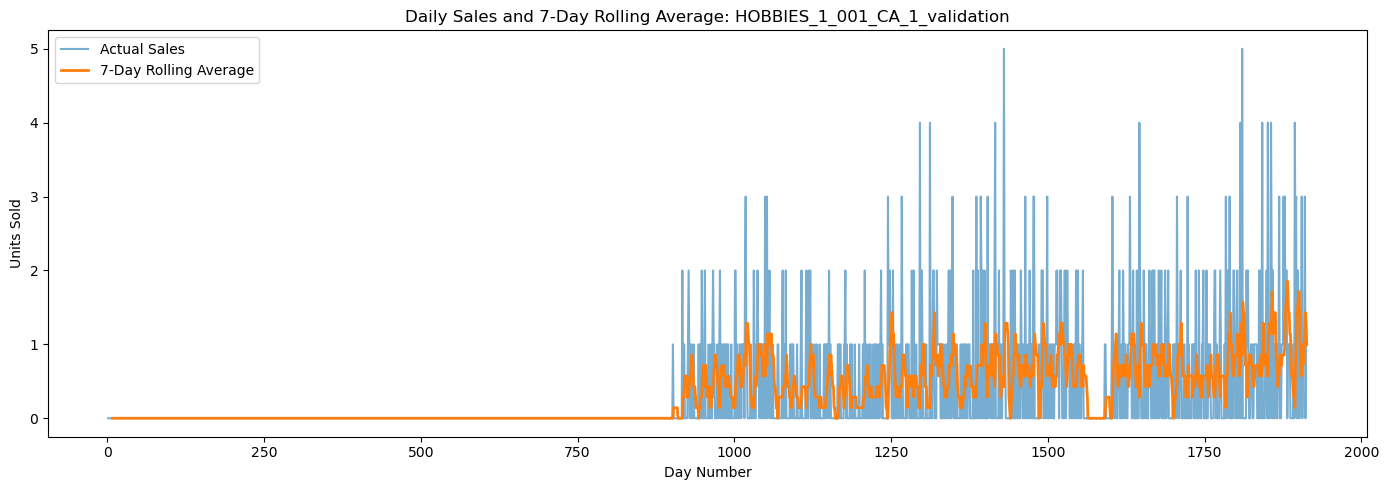

In [91]:
item = sample_long["id"].iloc[0]

item_data = sample_long[
    sample_long["id"] == item
].copy()

plt.figure(figsize=(14, 5))

plt.plot(
    item_data["day_number"],
    item_data["sales"],
    label="Actual Sales",
    alpha=0.6
)

plt.plot(
    item_data["day_number"],
    item_data["rolling_mean_7"],
    label="7-Day Rolling Average",
    linewidth=2
)
# Compare actual sales with the 7-day rolling average
plt.title(f"Daily Sales and 7-Day Rolling Average: {item}")
plt.xlabel("Day Number")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

### importing and merging calendar data 

In [92]:
calendar = pd.read_csv(
    "../data/raw/m5-forecasting-accuracy/calendar.csv"
)

calendar[["d", "date", "weekday"]].head()

,d,date,weekday
0,d_1,2011-01-29,Saturday
1,d_2,2011-01-30,Sunday
2,d_3,2011-01-31,Monday
3,d_4,2011-02-01,Tuesday
4,d_5,2011-02-02,Wednesday


In [93]:
sample_long = sample_long.merge(
    calendar[["d", "weekday"]],
    on="d",
    how="left",
    validate="many_to_one"
)

In [94]:
weekday_mapping = {
    "Monday": 0,
    "Tuesday": 1,
    "Wednesday": 2,
    "Thursday": 3,
    "Friday": 4,
    "Saturday": 5,
    "Sunday": 6
}

sample_long["day_of_week"] = (
    sample_long["weekday"].map(weekday_mapping)
)

In [95]:
sample_long[
    ["d", "weekday", "day_of_week", "sales"]
].head(15)

,d,weekday,day_of_week,sales
0,d_1,Saturday,5,0
1,d_2,Sunday,6,0
2,d_3,Monday,0,0
3,d_4,Tuesday,1,0
4,d_5,Wednesday,2,0
5,d_6,Thursday,3,0
6,d_7,Friday,4,0
7,d_8,Saturday,5,0
8,d_9,Sunday,6,0
9,d_10,Monday,0,0


In [96]:
sample_long.head(10)

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,day_number,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28,weekday,day_of_week
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,1,NaN,NaN,NaN,NaN,NaN,Saturday,5
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2,0.0,NaN,NaN,NaN,NaN,Sunday,6
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,3,0.0,NaN,NaN,NaN,NaN,Monday,0
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,4,0.0,NaN,NaN,NaN,NaN,Tuesday,1
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,5,0.0,NaN,NaN,NaN,NaN,Wednesday,2
5,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_6,0,6,0.0,NaN,NaN,NaN,NaN,Thursday,3
6,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_7,0,7,0.0,NaN,NaN,NaN,NaN,Friday,4
7,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_8,0,8,0.0,0.0,NaN,0.0,NaN,Saturday,5
8,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_9,0,9,0.0,0.0,NaN,0.0,NaN,Sunday,6
9,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_10,0,10,0.0,0.0,NaN,0.0,NaN,Monday,0


In [97]:
sample_long[
    [
        "id",
        "day_number",
        "sales",
        "lag_1",
        "lag_7",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28",
        "weekday",
        "day_of_week"
    ]
].tail(10)

,id,day_number,sales,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28,weekday,day_of_week
191290,HOBBIES_1_104_CA_1_validation,1904,0,0.0,1.0,0.0,0.285714,0.321429,Friday,4
191291,HOBBIES_1_104_CA_1_validation,1905,1,0.0,0.0,0.0,0.142857,0.321429,Saturday,5
191292,HOBBIES_1_104_CA_1_validation,1906,1,1.0,1.0,0.0,0.285714,0.357143,Sunday,6
191293,HOBBIES_1_104_CA_1_validation,1907,0,1.0,0.0,0.0,0.285714,0.392857,Monday,0
191294,HOBBIES_1_104_CA_1_validation,1908,0,0.0,0.0,0.0,0.285714,0.392857,Tuesday,1
191295,HOBBIES_1_104_CA_1_validation,1909,0,0.0,0.0,1.0,0.285714,0.392857,Wednesday,2
191296,HOBBIES_1_104_CA_1_validation,1910,0,0.0,0.0,0.0,0.285714,0.357143,Thursday,3
191297,HOBBIES_1_104_CA_1_validation,1911,0,0.0,0.0,1.0,0.285714,0.357143,Friday,4
191298,HOBBIES_1_104_CA_1_validation,1912,0,0.0,1.0,1.0,0.285714,0.321429,Saturday,5
191299,HOBBIES_1_104_CA_1_validation,1913,2,0.0,1.0,1.0,0.142857,0.285714,Sunday,6


In [98]:
feature_columns = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week"
]

sample_long[feature_columns].isnull().sum()

lag_1               100
lag_7               700
lag_28             2800
rolling_mean_7      700
rolling_mean_28    2800
day_of_week           0
dtype: int64

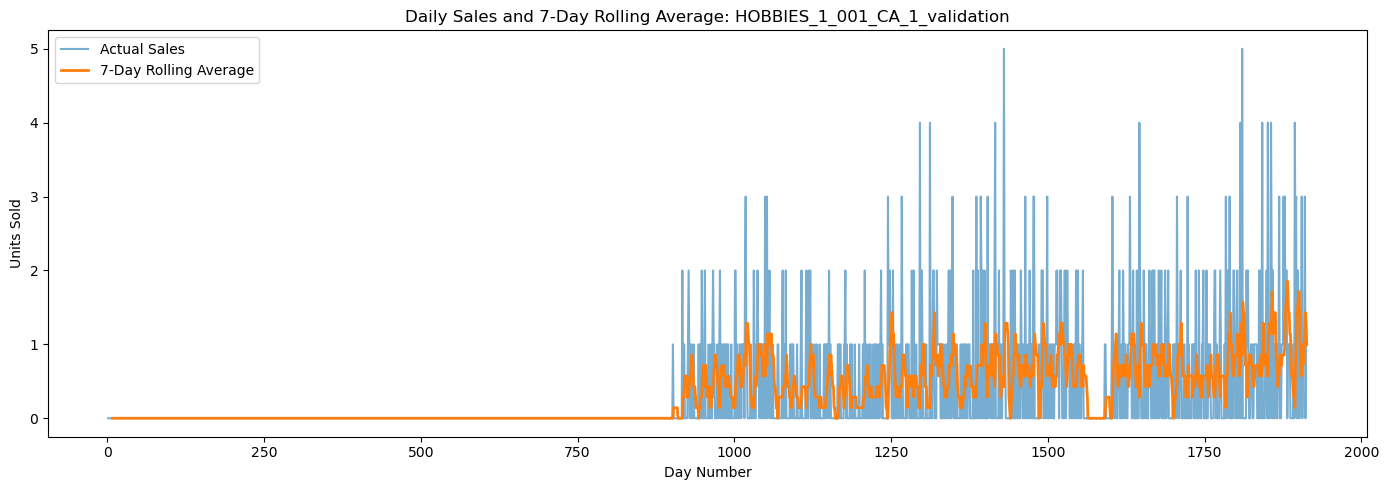

In [99]:
item = sample_long["id"].iloc[0]

item_data = sample_long[
    sample_long["id"] == item
].copy()

plt.figure(figsize=(14, 5))

plt.plot(
    item_data["day_number"],
    item_data["sales"],
    label="Actual Sales",
    alpha=0.6
)

plt.plot(
    item_data["day_number"],
    item_data["rolling_mean_7"],
    label="7-Day Rolling Average",
    linewidth=2
)

plt.title(f"Daily Sales and 7-Day Rolling Average: {item}")
plt.xlabel("Day Number")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()

### Investigate the zero-sale days 

In [100]:
item = sample_long["id"].iloc[0]

item_data = sample_long[
    sample_long["id"] == item
].copy()

total_days = len(item_data)
zero_sales_days = (item_data["sales"] == 0).sum()
nonzero_sales_days = (item_data["sales"] > 0).sum()

print("Product-store:", item)
print("Total days:", total_days)
print("Zero-sales days:", zero_sales_days)
print("Nonzero-sales days:", nonzero_sales_days)
print("Percentage of zero-sales days:",
      round(zero_sales_days / total_days * 100, 2), "%")

Product-store: HOBBIES_1_001_CA_1_validation
Total days: 1913
Zero-sales days: 1492
Nonzero-sales days: 421
Percentage of zero-sales days: 77.99 %


In [101]:
zero_sales_analysis = (
    sample_long.groupby("id")
    .agg(
        total_days=("sales", "count"),
        zero_sales_days=("sales", lambda x: (x == 0).sum()),
        nonzero_sales_days=("sales", lambda x: (x > 0).sum()),
        total_sales=("sales", "sum"),
        average_daily_sales=("sales", "mean")
    )
)

zero_sales_analysis["zero_sales_percentage"] = (
    zero_sales_analysis["zero_sales_days"]
    / zero_sales_analysis["total_days"] * 100
)

zero_sales_analysis = zero_sales_analysis.sort_values(
    "zero_sales_percentage", ascending=False
)

zero_sales_analysis.head(10).round(2)

,total_days,zero_sales_days,nonzero_sales_days,total_sales,average_daily_sales,zero_sales_percentage
id,,,,,,
HOBBIES_1_026_CA_1_validation,1913,1894,19,21,0.01,99.01
HOBBIES_1_018_CA_1_validation,1913,1834,79,88,0.05,95.87
HOBBIES_1_062_CA_1_validation,1913,1827,86,117,0.06,95.50
HOBBIES_1_053_CA_1_validation,1913,1813,100,160,0.08,94.77
HOBBIES_1_052_CA_1_validation,1913,1800,113,124,0.06,94.09
HOBBIES_1_011_CA_1_validation,1913,1784,129,142,0.07,93.26
HOBBIES_1_070_CA_1_validation,1913,1767,146,166,0.09,92.37
HOBBIES_1_065_CA_1_validation,1913,1760,153,166,0.09,92.00
HOBBIES_1_054_CA_1_validation,1913,1744,169,195,0.10,91.17


In [102]:
overall_zero_sales = (
    sample_long.groupby("id")
    .agg(
        total_days=("sales", "count"),
        zero_sales_days=("sales", lambda x: (x == 0).sum()),
        total_sales=("sales", "sum")
    )
)

overall_zero_sales["zero_sales_percentage"] = (
    overall_zero_sales["zero_sales_days"]
    / overall_zero_sales["total_days"] * 100
)

print("Number of product-store combinations:",
      len(overall_zero_sales))

print("Average zero-sales percentage:",
      round(overall_zero_sales["zero_sales_percentage"].mean(), 2), "%")

print("Median zero-sales percentage:",
      round(overall_zero_sales["zero_sales_percentage"].median(), 2), "%")

print("Products with >80% zero-sales days:",
      (overall_zero_sales["zero_sales_percentage"] > 80).sum())

print("Products with >90% zero-sales days:",
      (overall_zero_sales["zero_sales_percentage"] > 90).sum())

Number of product-store combinations: 100
Average zero-sales percentage: 65.42 %
Median zero-sales percentage: 67.69 %
Products with >80% zero-sales days: 31
Products with >90% zero-sales days: 12


### Reload the original dataset

In [103]:
sales = pd.read_csv(
    "../data/raw/m5-forecasting-accuracy/sales_train_validation.csv"
)

print("Original dataset shape:", sales.shape)

Original dataset shape: (30490, 1919)


### Check the original dataset's diversity

In [104]:
print("Categories:")
print(sales["cat_id"].value_counts())

print("\nDepartments:")
print(sales["dept_id"].value_counts())

print("\nStores:")
print(sales["store_id"].value_counts())

print("\nStates:")
print(sales["state_id"].value_counts())

Categories:
cat_id
FOODS        14370
HOUSEHOLD    10470
HOBBIES       5650
Name: count, dtype: int64

Departments:
dept_id
FOODS_3        8230
HOUSEHOLD_1    5320
HOUSEHOLD_2    5150
HOBBIES_1      4160
FOODS_2        3980
FOODS_1        2160
HOBBIES_2      1490
Name: count, dtype: int64

Stores:
store_id
CA_1    3049
CA_2    3049
CA_3    3049
CA_4    3049
TX_1    3049
TX_2    3049
TX_3    3049
WI_1    3049
WI_2    3049
WI_3    3049
Name: count, dtype: int64

States:
state_id
CA    12196
TX     9147
WI     9147
Name: count, dtype: int64


In [105]:
# Select 1,000 product-store combinations reproducibly
sample = sales.sample(
    n=1000,
    random_state=42
).copy()
# Check sample diversity
print("Sample shape:", sample.shape)

print("\nCategories:")
print(sample["cat_id"].value_counts())

print("\nDepartments:")
print(sample["dept_id"].value_counts())

print("\nStores:")
print(sample["store_id"].value_counts())

print("\nStates:")
print(sample["state_id"].value_counts())

Sample shape: (1000, 1919)

Categories:
cat_id
FOODS        474
HOUSEHOLD    325
HOBBIES      201
Name: count, dtype: int64

Departments:
dept_id
FOODS_3        281
HOUSEHOLD_2    169
HOUSEHOLD_1    156
HOBBIES_1      141
FOODS_2        136
HOBBIES_2       60
FOODS_1         57
Name: count, dtype: int64

Stores:
store_id
TX_1    128
CA_4    116
CA_2    110
WI_2    100
CA_3     99
WI_3     98
WI_1     90
TX_2     89
TX_3     88
CA_1     82
Name: count, dtype: int64

States:
state_id
CA    407
TX    305
WI    288
Name: count, dtype: int64


### melting feature 

In [106]:
# Identify daily sales columns
daily_columns = [
    col for col in sample.columns
    if col.startswith("d_")
]

# Convert wide data into long format
sample_long2 = sample.melt(
    id_vars=[
        "id", "item_id", "dept_id",
        "cat_id", "store_id", "state_id"
    ],
    value_vars=daily_columns,
    var_name="d",
    value_name="sales"
)

# Extract numeric day number
sample_long2["day_number"] = (
    sample_long2["d"]
    .str.replace("d_", "", regex=False)
    .astype("int16")
)

# Sort chronologically within each product-store series
sample_long2 = sample_long2.sort_values(
    ["id", "day_number"]
).reset_index(drop=True)

print("Long-format shape:", sample_long.shape)
print("Unique product-store combinations:", sample_long["id"].nunique())
print("Day number range:",
      sample_long2["day_number"].min(),
      "to",
      sample_long2["day_number"].max())

Long-format shape: (191300, 16)
Unique product-store combinations: 100
Day number range: 1 to 1913


##### The first 100 rows came from the beginning of the dataset and didn't provide sufficiently broad coverage of its different categories and stores.

##### So we randomly selected 1,000 product-store combinations.

##### That gave us 1,913,000 rows after melting.

### wahii lag feature aur rolling avg 

In [107]:
# Create lag features separately for each product-store combination

sample_long2["lag_1"] = (
    sample_long2.groupby("id")["sales"].shift(1)
)

sample_long2["lag_7"] = (
    sample_long2.groupby("id")["sales"].shift(7)
)

sample_long2["lag_28"] = (
    sample_long2.groupby("id")["sales"].shift(28)
)

# Create rolling averages using historical sales only

sample_long2["rolling_mean_7"] = (
    sample_long2.groupby("id")["sales"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

sample_long2["rolling_mean_28"] = (
    sample_long2.groupby("id")["sales"]
    .transform(lambda x: x.shift(1).rolling(28).mean())
)

print("Feature engineering completed!")
print("Dataset shape:", sample_long.shape)

Feature engineering completed!
Dataset shape: (191300, 16)


In [108]:
sample_long2[
    [
        "id",
        "day_number",
        "sales",
        "lag_1",
        "lag_7",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28"
    ]
].tail(10)

,id,day_number,sales,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28
1912990,HOUSEHOLD_2_516_WI_2_validation,1904,0,0.0,0.0,0.0,0.000000,0.000000
1912991,HOUSEHOLD_2_516_WI_2_validation,1905,0,0.0,0.0,0.0,0.000000,0.000000
1912992,HOUSEHOLD_2_516_WI_2_validation,1906,0,0.0,0.0,0.0,0.000000,0.000000
1912993,HOUSEHOLD_2_516_WI_2_validation,1907,0,0.0,0.0,0.0,0.000000,0.000000
1912994,HOUSEHOLD_2_516_WI_2_validation,1908,0,0.0,0.0,0.0,0.000000,0.000000
1912995,HOUSEHOLD_2_516_WI_2_validation,1909,0,0.0,0.0,0.0,0.000000,0.000000
1912996,HOUSEHOLD_2_516_WI_2_validation,1910,1,0.0,0.0,0.0,0.000000,0.000000
1912997,HOUSEHOLD_2_516_WI_2_validation,1911,0,1.0,0.0,0.0,0.142857,0.035714
1912998,HOUSEHOLD_2_516_WI_2_validation,1912,0,0.0,0.0,0.0,0.142857,0.035714
1912999,HOUSEHOLD_2_516_WI_2_validation,1913,0,0.0,0.0,0.0,0.142857,0.035714


### Adding Calendar feature 

In [109]:
calendar = pd.read_csv(
    "../data/raw/m5-forecasting-accuracy/calendar.csv"
)

sample_long2 = sample_long2.merge(
    calendar[
        [
            "d",
            "date",
            "weekday",
            "event_name_1",
            "event_type_1",
            "event_name_2",
            "event_type_2",
            "snap_CA",
            "snap_TX",
            "snap_WI"
        ]
    ],
    on="d",
    how="left",
    validate="many_to_one"
)

In [113]:
print("Shape:", sample_long2.shape)

sample_long2[
    [
        "d",
        "date",
        "weekday",
        "event_name_1",
        "snap_CA",
        "snap_TX",
        "snap_WI"
    ]
].head()
## Sales can vary depending on the day of the week, special events, and SNAP purchasing-program indicators.
# SNAP stands for Supplemental Nutrition Assistance Program.
# snap_CA	SNAP indicator for California
# snap_TX	SNAP indicator for Texas
# snap_WI	SNAP indicator for Wisconsin

Shape: (1913000, 23)


,d,date,weekday,event_name_1,snap_CA,snap_TX,snap_WI
0,d_1,2011-01-29,Saturday,NaN,0,0,0
1,d_2,2011-01-30,Sunday,NaN,0,0,0
2,d_3,2011-01-31,Monday,NaN,0,0,0
3,d_4,2011-02-01,Tuesday,NaN,1,1,0
4,d_5,2011-02-02,Wednesday,NaN,1,0,1


### NUmerical calendar feautures

In [114]:
# Convert weekday names into numbers
weekday_mapping = {
    "Monday": 0,
    "Tuesday": 1,
    "Wednesday": 2,
    "Thursday": 3,
    "Friday": 4,
    "Saturday": 5,
    "Sunday": 6
}

sample_long2["day_of_week"] = sample_long2["weekday"].map(weekday_mapping)

# Extract month from the date
sample_long2["date"] = pd.to_datetime(sample_long2["date"])
sample_long2["month"] = sample_long2["date"].dt.month

# Check the results
sample_long2[
    ["date", "weekday", "day_of_week", "month"]
].head(10)

,date,weekday,day_of_week,month
0,2011-01-29,Saturday,5,1
1,2011-01-30,Sunday,6,1
2,2011-01-31,Monday,0,1
3,2011-02-01,Tuesday,1,2
4,2011-02-02,Wednesday,2,2
5,2011-02-03,Thursday,3,2
6,2011-02-04,Friday,4,2
7,2011-02-05,Saturday,5,2
8,2011-02-06,Sunday,6,2
9,2011-02-07,Monday,0,2


### Create an event indicator 

In [116]:
sample_long2["is_event"] = (
    sample_long2["event_name_1"].notna()
    | sample_long2["event_name_2"].notna()
).astype("int8")

sample_long2["is_event"].value_counts()
# 1:- At least one event name is recorded for that date.

is_event
0    1759000
1     154000
Name: count, dtype: int64

## VERYFYING AND CHECKING THE FEATURES

### Checking the feature quality 

In [117]:
# Check the dataset shape
print("Dataset shape:", sample_long2.shape)

# Check missing values in our engineered features
feature_columns = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "is_event"
]

print("\nMissing values:")
print(sample_long2[feature_columns].isnull().sum())

print("\nData types:")
print(sample_long2[feature_columns].dtypes)

Dataset shape: (1913000, 26)

Missing values:
lag_1               1000
lag_7               7000
lag_28             28000
rolling_mean_7      7000
rolling_mean_28    28000
day_of_week            0
month                  0
is_event               0
dtype: int64

Data types:
lag_1              float64
lag_7              float64
lag_28             float64
rolling_mean_7     float64
rolling_mean_28    float64
day_of_week          int64
month                int32
is_event              int8
dtype: object


### Verifying our feature on one product

In [125]:
# Select the first product-store combination
first_id = sample_long2["id"].iloc[0]

# Display its sales and engineered features
sample_long2.loc[
    sample_long2["id"] == first_id,
    [
        "id",
        "day_number",
        "sales",
        "lag_1",
        "lag_7",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28",
        "day_of_week",
        "month",
        "is_event"
    ]
].head(35)

,id,day_number,sales,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28,day_of_week,month,is_event
0,FOODS_1_003_TX_3_validation,1,1,NaN,NaN,NaN,NaN,NaN,5,1,0
1,FOODS_1_003_TX_3_validation,2,0,1.0,NaN,NaN,NaN,NaN,6,1,0
2,FOODS_1_003_TX_3_validation,3,0,0.0,NaN,NaN,NaN,NaN,0,1,0
3,FOODS_1_003_TX_3_validation,4,2,0.0,NaN,NaN,NaN,NaN,1,2,0
4,FOODS_1_003_TX_3_validation,5,0,2.0,NaN,NaN,NaN,NaN,2,2,0
5,FOODS_1_003_TX_3_validation,6,0,0.0,NaN,NaN,NaN,NaN,3,2,0
6,FOODS_1_003_TX_3_validation,7,0,0.0,NaN,NaN,NaN,NaN,4,2,0
7,FOODS_1_003_TX_3_validation,8,1,0.0,1.0,NaN,0.428571,NaN,5,2,0
8,FOODS_1_003_TX_3_validation,9,0,1.0,0.0,NaN,0.428571,NaN,6,2,1
9,FOODS_1_003_TX_3_validation,10,0,0.0,0.0,NaN,0.428571,NaN,0,2,0


### LAG

In [126]:
first_id = sample_long2["id"].iloc[0]

check = sample_long2.loc[
    sample_long2["id"] == first_id,
    ["day_number", "sales", "lag_1", "lag_7"]
].head(10)

check

,day_number,sales,lag_1,lag_7
0,1,1,NaN,NaN
1,2,0,1.0,NaN
2,3,0,0.0,NaN
3,4,2,0.0,NaN
4,5,0,2.0,NaN
5,6,0,0.0,NaN
6,7,0,0.0,NaN
7,8,1,0.0,1.0
8,9,0,1.0,0.0
9,10,0,0.0,0.0


## REview all engineered features

In [127]:
# Display all columns
print(sample_long2.columns.tolist())

# Preview the final dataset
sample_long2[
    [
        "id",
        "date",
        "sales",
        "lag_1",
        "lag_7",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28",
        "day_of_week",
        "month",
        "is_event",
        "snap_CA",
        "snap_TX",
        "snap_WI"
    ]
].tail(10)

['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'day_number', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'date', 'weekday', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'day_of_week', 'month', 'is_event']


,id,date,sales,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28,day_of_week,month,is_event,snap_CA,snap_TX,snap_WI
1912990,HOUSEHOLD_2_516_WI_2_validation,2016-04-15,0,0.0,0.0,0.0,0.000000,0.000000,4,4,0,0,1,1
1912991,HOUSEHOLD_2_516_WI_2_validation,2016-04-16,0,0.0,0.0,0.0,0.000000,0.000000,5,4,0,0,0,0
1912992,HOUSEHOLD_2_516_WI_2_validation,2016-04-17,0,0.0,0.0,0.0,0.000000,0.000000,6,4,0,0,0,0
1912993,HOUSEHOLD_2_516_WI_2_validation,2016-04-18,0,0.0,0.0,0.0,0.000000,0.000000,0,4,0,0,0,0
1912994,HOUSEHOLD_2_516_WI_2_validation,2016-04-19,0,0.0,0.0,0.0,0.000000,0.000000,1,4,0,0,0,0
1912995,HOUSEHOLD_2_516_WI_2_validation,2016-04-20,0,0.0,0.0,0.0,0.000000,0.000000,2,4,0,0,0,0
1912996,HOUSEHOLD_2_516_WI_2_validation,2016-04-21,1,0.0,0.0,0.0,0.000000,0.000000,3,4,0,0,0,0
1912997,HOUSEHOLD_2_516_WI_2_validation,2016-04-22,0,1.0,0.0,0.0,0.142857,0.035714,4,4,0,0,0,0
1912998,HOUSEHOLD_2_516_WI_2_validation,2016-04-23,0,0.0,0.0,0.0,0.142857,0.035714,5,4,0,0,0,0
1912999,HOUSEHOLD_2_516_WI_2_validation,2016-04-24,0,0.0,0.0,0.0,0.142857,0.035714,6,4,0,0,0,0


### Check whether our sample covers all categories

In [128]:
print("Categories:")
print(sample_long2["cat_id"].value_counts())

print("\nStores:")
print(sample_long2["store_id"].value_counts())

print("\nStates:")
print(sample_long2["state_id"].value_counts())

Categories:
cat_id
FOODS        906762
HOUSEHOLD    621725
HOBBIES      384513
Name: count, dtype: int64

Stores:
store_id
TX_1    244864
CA_4    221908
CA_2    210430
WI_2    191300
CA_3    189387
WI_3    187474
WI_1    172170
TX_2    170257
TX_3    168344
CA_1    156866
Name: count, dtype: int64

States:
state_id
CA    778591
TX    583465
WI    550944
Name: count, dtype: int64


### Check the dataset's range

In [130]:
print("First date:", sample_long2["date"].min())
print("Last date:", sample_long2["date"].max())

print("Unique dates:", sample_long2["date"].nunique())
print("Unique product-store combinations:", sample_long2["id"].nunique())

First date: 2011-01-29 00:00:00
Last date: 2016-04-24 00:00:00
Unique dates: 1913
Unique product-store combinations: 1000


#### CHEcking for duplicate product-date records

In [131]:
# Check for duplicate product-date records
duplicates = sample_long2.duplicated(
    subset=["id", "date"]
).sum()

print("Duplicate product-date records:", duplicates)

# Check the number of rows per product-store combination
rows_per_id = sample_long2.groupby("id").size()

print("\nMinimum rows per combination:", rows_per_id.min())
print("Maximum rows per combination:", rows_per_id.max())

Duplicate product-date records: 0

Minimum rows per combination: 1913
Maximum rows per combination: 1913


### GREAT < everythine is fine 

# SAVE the dataset

In [133]:
from pathlib import Path

output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)
#It's generally more storage-efficient and faster to load than CSV for a dataset with 1.9 million rows.
sample_long2.to_parquet(
    output_path / "feature_engineered_sample.parquet",
    index=False
)

print("Dataset saved successfully!")
print("Rows:", len(sample_long2))
print("File:", output_path / "feature_engineered_sample.parquet")

Dataset saved successfully!
Rows: 1913000
File: ..\data\processed\feature_engineered_sample.parquet
